# All-Optical Switching of GdFeCo with the Extended LLB

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/04-magnetization/04-eLLB.ipynb)

Here, the deterministic all-optical switching (AOS) of a GdFeCo ferrimagnet of {cite:t}`raposo2022` is reproduced with the extended two-sublattice Landau-Lifshitz-Bloch equation (eLLB): a two-temperature model solved by the {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>` class drives the {py:class}`LLB <udkm1Dsim.simulations.magnetization.LLB>` with its exchange-relaxation torque switched on (`exchange_relaxation=True`), which resolves the dynamics of both sublattices through the transient ferromagnetic-like state.

:::{admonition} References {cite}`raposo2022,radu2011,atxitia2012,mentink2012,baryakhtar2013`
:class: seealso
V. Raposo, F. García-Sánchez, U. Atxitia, and E. Martínez,
*Realistic micromagnetic description of all-optical ultrafast switching processes in ferrimagnetic alloys*,
[Phys. Rev. B 105, 104432 (2022)](https://doi.org/10.1103/PhysRevB.105.104432)

I. Radu et al.,
*Transient ferromagnetic-like state mediating ultrafast reversal of antiferromagnetically coupled spins*,
[Nature 472, 205 (2011)](https://doi.org/10.1038/nature09901)

U. Atxitia, P. Nieves, and O. Chubykalo-Fesenko,
*Landau-Lifshitz-Bloch equation for ferrimagnetic materials*,
[Phys. Rev. B 86, 104414 (2012)](https://doi.org/10.1103/PhysRevB.86.104414)

J. H. Mentink et al.,
*Ultrafast spin dynamics in multisublattice magnets*,
[Phys. Rev. Lett. 108, 057202 (2012)](https://doi.org/10.1103/PhysRevLett.108.057202)

V. G. Bar'yakhtar, V. I. Butrim, and B. A. Ivanov,
*Exchange relaxation as a mechanism of the ultrafast reorientation of spins in a two-sublattice ferrimagnet*,
[JETP Lett. 98, 289 (2013)](https://doi.org/10.1134/S0021364013180057)
:::

## The Model

A ferrimagnet consists of two antiferromagnetically coupled sublattices - here the transition metal (TM, FeCo) and the rare earth (RE, Gd) - with different magnetic moments and different demagnetization speeds.
In **udkm1Dsim** every magnetic {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` can carry several magnetic sublattices, see the [simple antiferromagnet of the LLB example](#example_LLB): the magnetic parameters accept one value per sublattice and the `mf_exch_coupling` matrix $J_{0,ab}$ couples them, with negative off-diagonal elements for the antiferromagnetic coupling.

The LLB of {cite:t}`raposo2022` (their Supplemental Eq. (eS7)) reads for each sublattice $i$

$$
\frac{d\mathbf{m}_i}{dt} = -\gamma' \mathbf{m}_i \times \mathbf{B}_i
    - \frac{\gamma'\alpha_i^\perp}{m_i^2} \mathbf{m}_i \times (\mathbf{m}_i \times \mathbf{B}_i)
    + \frac{\gamma'\alpha_i^\parallel}{m_i^2} (\mathbf{m}_i \cdot \mathbf{B}_i) \mathbf{m}_i
    + \boldsymbol{\tau}_i^\mathrm{NE}.
$$

The first three terms are the conventional LLB: precession, transverse and longitudinal relaxation towards the bath.
The field $\mathbf{B}_i$ contains the anisotropy, the transverse inter-sublattice exchange and the longitudinal field $\mathbf{B}_i^\parallel \parallel \mathbf{m}_i$, which pulls the amplitude of each sublattice towards its equilibrium magnetization $m_{\mathrm{eq},i}(T)$, i.e. the reduced amplitude of the sublattice in the mean-field equilibrium at the temperature $T$, with the longitudinal susceptibility $\chi_i(T)$.
Infinite effective spins give the classical LLB with the Langevin function, which is the model of the paper and of the atomistic spin simulations it is compared to.
These relaxation terms transfer angular momentum from each sublattice to the electron and phonon bath only.
They can quench a sublattice to zero but never reverse its sign, because the exchange field a sublattice feels from the other one always points along the *current* direction of that other sublattice.

The reversal needs a second dissipative channel that transfers angular momentum *directly between* the sublattices {cite}`mentink2012,baryakhtar2013`, the exchange-relaxation torque (Eq. (5) of the main text), see {py:func}`exchange_relaxation_torque <udkm1Dsim.simulations.solvers.magnetization_scipy.exchange_relaxation_torque>`,

$$
\boldsymbol{\tau}_i^\mathrm{NE} = \gamma'\lambda_\mathrm{ex} \alpha_i^\parallel 
    \frac{x_i\mu_i m_i + x_j\mu_j m_j}{\mu_i m_i \mu_j m_j} 
    \left(\mu_i\mathbf{B}_i^\parallel - \mu_j\mathbf{B}_j^\parallel\right)
$$

with $j$ being the index of the other sublattice, the concentrations $x_i$ (the magnetic parameter `concentration`, which can also be taken from the fractions of an {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>`), the atomic moments $\mu_i$ and the single phenomenological rate $\lambda_\mathrm{ex}$ (`exch_relax_rate`, 0.013 in the paper).
After the pulse the fast TM sublattice is quenched while the slow RE sublattice with its large moment is still far *above* its equilibrium at the high electron temperature, so $\mathbf{B}_\mathrm{RE}^\parallel$ is large.
The bracket diverges as $1/m_\mathrm{TM}$, the RE dumps its excess angular momentum into the TM, which is polarized *along the RE*, i.e. reversed - the transient ferromagnetic-like state {cite}`radu2011`.
As the electrons cool, the exchange field of the reversed TM drags the RE along and both sublattices end up reversed.

:::{important}
Two points that decide between a working and a silently wrong simulation:

1. **Exchange matrix.** The exchange energies quoted in the Supplemental of the paper are the *atomistic* ones. The mean-field matrix is $J_{0,ii} = z x_i J_{i\text{-}i}$ and $J_{0,ij} = z x_j J_{i\text{-}j}$ with $z = 12$ neighbours, which yields the classical ordering temperature $T_C = 603$ K of the paper. Taking the quoted values directly gives $T_C = 79$ K.
2. **$m = 0$ is an exact fixed point.** Without an external field every term of the LLB is proportional to $\mathbf{m}$. A sublattice that reaches zero in floating point stays there for the rest of the run, without any error - the `LLB` warns when this happens.

The torque runs through a $1/m$ singularity when a sublattice is quenched.
The adaptive integrators of the `ode_options`, whose step is limited to the delay grid, carry the switching through, which can be checked by tighter tolerances, see below.
The direction, in which a sublattice leaves $m \approx 0$, is however undetermined in this deterministic model.
:::

:::{note}
The material parameters are the micromagnetic set (Supplemental SN1/SN2) of {cite:t}`raposo2022`.
Instead of the uniform absorbed power density and the phenomenological cooling of the electrons of the paper, the film on a glass substrate is excited by a typical heat simulation of **udkm1Dsim**, which reproduces the qualitative results of the paper.
:::

## Setup

Do all necessary imports and settings.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

from udkm1Dsim.simulations.solvers import mean_field

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

The GdFeCo film is a {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` of 75 % FeCo and 25 % Gd built from its parameter groups.
Its {py:class}`MagneticParameters <udkm1Dsim.structures.parameter_groups.MagneticParameters>` describe two sublattices by one value per sublattice, the TM first and the RE second.
The initial magnetizations of the sublattices are given as list - the TM along $+z$, the RE along $-z$ - and the concentrations $x_i$ of the exchange-relaxation torque explicitly.
For an {py:class}`AmorphousLayer <udkm1Dsim.structures.layers.AmorphousLayer>` with an {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>` of as many constituents as sublattices, both would be taken from the constituents and their fractions.

The two-temperature model of the paper (main text Eqs. (2)-(3)) has the electronic heat capacity $C_e = \gamma_e T_e$ with $\gamma_e = 1.8\times10^5/300$ J/(m³K²), the phonon heat capacity $C_l = 3.8\times10^6$ J/(m³K), and the electron-phonon coupling $g_{el} = 7\times10^{17}$ W/(m³K).
The **udkm1Dsim** toolbox takes the heat capacities per mass, so they are divided by the density.
The 10 nm thick GdFeCo film is deposited on a glass substrate, which takes up the heat of the phonons, but not of the electrons.

In [2]:
# --- magnetic parameters of Gd_0.25(FeCo)_0.75, Raposo et al. Supplemental SN1/SN2
x = np.array([0.75, 0.25])  # concentrations [TM, RE]
z = 12  # fcc nearest neighbours
# atomistic exchange energies [[TM-TM, TM-RE], [RE-TM, RE-RE]]
J_atom = [[2.59, -1.13], [-1.13, 1.35]] * u.zJ
# mean-field exchange matrix J0_ij = z x_j J_(i-j); row i: field on sublattice i
J0 = z * x * J_atom
mu = [1.92, 7.63] * u.bohr_magneton  # atomic moments
lamda = [0.02, 0.02]  # coupling to the bath
lamda_ex = 0.013  # exchange-relaxation rate
K_u = [1.87e6, 0.62e6] * u.J / u.m**3  # uniaxial anisotropy along z
A_ex = 3.2e-12 * u.J / u.m  # exchange stiffness
a_lat, p_f = 0.35 * u.nm, 0.74  # lattice constant and fcc packing factor
v_atom = p_f * a_lat**3
Ms = (x * mu / v_atom).to("A/m")  # sublattice saturation magnetizations

# --- two-temperature model, Raposo et al. main text Eqs. (2)-(3)
rho = 8000 * u.kg / u.m**3  # density, cancels in the volumetric heat capacities
gamma_e = 1.8e5 * u.J / (u.m**3 * u.K) / (300 * u.K)  # C_e = gamma_e T_e
C_l = 3.8e6 * u.J / (u.m**3 * u.K)  # phonon heat capacity
g_el = 7e17 * u.W / (u.m**3 * u.K)  # electron-phonon coupling

layer_GdFeCo = ud.Layer(
    "GdFeCo",
    "GdFeCo amorphous",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{(gamma_e / rho).m_as('J/(kg*K**2)'):g}*T", C_l / rho],
        therm_cond=[20 * u.W / (u.m * u.K), 1 * u.W / (u.m * u.K)],
        sub_system_coupling=[
            f"-{g_el.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
            f"{g_el.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
        ],
        lin_therm_exp=[0, 1e-5 / u.K],
        sub_system_labels=["e", "p"],
    ),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(3.0 + 3.5j)),
    # two sublattices [TM, RE]
    magnetic=ud.MagneticParameters(
        # infinite effective spins select the classical (Langevin) LLB of the paper
        eff_spin=[np.inf, np.inf],
        mag_moment=mu,
        lamda=lamda,
        mf_exch_coupling=J0,
        mag_saturation=Ms,
        anisotropy=[[0, 0, 1], [0, 0, 1]] * K_u[:, np.newaxis],
        aniso_exponent=[2, 2],
        exch_stiffness=A_ex,
        exch_relax_rate=lamda_ex,
        concentration=x,
        magnetization=[(0, 0, 1), (0, 0, -1)],  # TM along +z, RE along -z
    ),
)

# glass substrate, which is not magnetic and has no electronic heat conduction
layer_glass = ud.Layer(
    "glass",
    "Glass",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=2540 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[1 * u.J / (u.kg * u.K), 709 * u.J / (u.kg * u.K)],
        therm_cond=[0, 1 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, 0.5e-6 / u.K],
        sub_system_labels=["e", "p"],
    ),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(1.45 + 0j)),
)

S = ud.Structure("GdFeCo on glass")
S.add_sub_structure(layer_GdFeCo, 10)  # 10 nm film
S.add_sub_structure(layer_glass, 20)
# add a semi-infinite, static glass substrate for the optical absorption
S.add_substrate(layer_glass)
_, _, distances = S.get_distances_of_layers()
select = S.get_all_positions_per_unique_layer()["GdFeCo"]

print(f"number of sublattices: {layer_GdFeCo.num_sublattices}")
print(f"classical ordering temperature: {layer_GdFeCo.curie_temp:.0f~P}  (paper: ~600 K)")
print(
    "saturation magnetizations: {:.2f} / {:.2f} MA/m  (paper: 0.41 / 0.55)".format(
        *Ms.m_as("MA/m")
    )
)
print("sublattice concentrations:", layer_GdFeCo.concentration)
signs = mean_field.sublattice_signs(J0.m_as("J"), [np.inf, np.inf])
print("sublattice signs of the collinear ground state:", signs)

number of sublattices: 2
classical ordering temperature: 603 K  (paper: ~600 K)
saturation magnetizations: 0.42 / 0.56 MA/m  (paper: 0.41 / 0.55)
sublattice concentrations: [0.75 0.25]
sublattice signs of the collinear ground state: [ 1. -1.]


## Landau-Lifshitz-Bloch Simulations

The {py:class}`LLB <udkm1Dsim.simulations.magnetization.LLB>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order to overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can be enabled using the boolean switch `progress_bar`.
Refer to the [LLG example](#example_LLG) for more details on the `ode_options`.

## Equilibrium Magnetization and Compensation Temperature

With infinite effective spins the LLB is classical: the equilibrium magnetizations of both sublattices are the solution of the coupled Langevin mean-field equations, see {py:meth}`get_sublattice_mean_field_mag_map <udkm1Dsim.simulations.magnetization.Magnetization.get_sublattice_mean_field_mag_map>`, and the ordering temperature of the layer is the classical one.
With the signs of the collinear ground state, the RE sublattice is antiparallel to the TM.
The net magnetization $\sum_a M_{s,a} m_a / \sum_a M_{s,a}$ crosses zero at the magnetization compensation temperature $T_M$, where the faster decaying RE sublattice loses its dominance.

In [3]:
llb = ud.LLB(S, True)

llb.save_data = False
llb.disp_messages = False
llb.progress_bar = False

llb

Landau-Lifshitz-Bloch Magnetization Dynamics simulation properties:

======================  =======
             parameter  value
======================  =======
          force recalc  True
       cache directory  ./
      display messages  False
             save data  False
          progress bar  False
temperature sub-system  0
======================  =======

This is the current structure for the simulations:

Structure properties:

Name   : GdFeCo on glass
Thickness : 30 nm
----
10 times GdFeCo amorphous: 10 nm
20 times Glass: 20 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times Glass: 1 nm

compensation temperature: 320 K
m_eq(300 K) = 0.801 (TM) / 0.624 (RE)  (paper: 0.801 / 0.623)


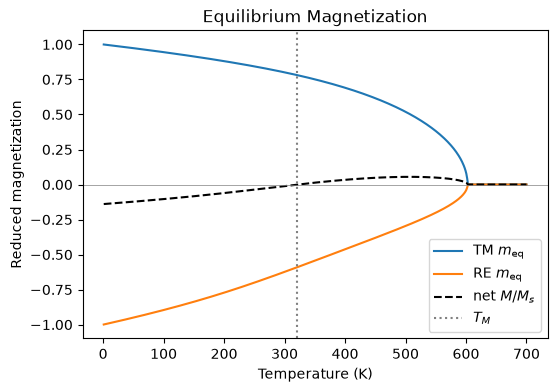

In [4]:
temps = np.linspace(1, 700, 500)
mf = llb.get_sublattice_mean_field_mag_map(np.tile(temps[:, np.newaxis], (1, len(distances))))
m_TM = signs[0] * mf[:, select[0], 0]
m_RE = signs[1] * mf[:, select[0], 1]
net = ((Ms[0] * m_TM + Ms[1] * m_RE) / (Ms[0] + Ms[1])).m_as("")
# the compensation temperature is the sign change of the net magnetization
# below the ordering temperature
ordered = np.abs(m_TM) > 1e-3
crossing = np.flatnonzero(np.diff(np.sign(net[ordered])))
T_M = temps[ordered][crossing[0]] if len(crossing) else np.nan
print(f"compensation temperature: {T_M:.0f} K")
k300 = np.argmin(np.abs(temps - 300))
print(f"m_eq(300 K) = {m_TM[k300]:.3f} (TM) / {-m_RE[k300]:.3f} (RE)  (paper: 0.801 / 0.623)")

plt.figure(figsize=[6, 4])
plt.plot(temps, m_TM, label=r"TM $m_\mathrm{eq}$")
plt.plot(temps, m_RE, label=r"RE $m_\mathrm{eq}$")
plt.plot(temps, net, "k--", label="net $M/M_s$")
plt.axhline(0, color="gray", lw=0.5)
plt.axvline(T_M, color="gray", ls=":", label="$T_M$")
plt.xlabel("Temperature (K)")
plt.ylabel("Reduced magnetization")
plt.title("Equilibrium Magnetization")
plt.legend()
plt.show()

## Laser Excitation

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

The film is excited by a 50 fs laser pulse at 800 nm under normal incidence and the electron temperature of the two-temperature model drives the eLLB.
Two fluences are compared, which are below and above the switching threshold.

In [5]:
h = ud.Heat(S, True)
h.save_data = False
h.disp_messages = False
h.progress_bar = False
h.heat_diffusion = True
h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
h.excitation = {
    "fluence": [1] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [50] * u.fs,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 90 * u.deg,
}

T_R = 300 * u.K  # initial temperature
delays = np.r_[-1:12:0.005] * u.ps
fluences = [1, 1.5]  # mJ/cm^2

temp_maps = {}
for fluence in fluences:
    h.excitation = {"fluence": [fluence] * u.mJ / u.cm**2}  # only the fluence changes
    temp_maps[fluence], _ = h.get_temp_map(delays, T_R)
    peak = temp_maps[fluence][:, select, 0].mean(axis=1).max()
    print(f"{fluence} mJ/cm²: peak electron temperature {peak:.0f} K")

1 mJ/cm²: peak electron temperature 1128 K
1.5 mJ/cm²: peak electron temperature 1372 K


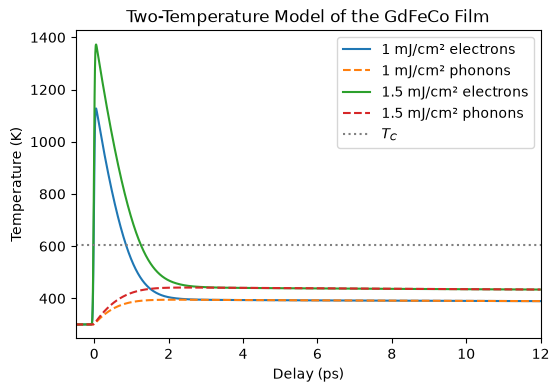

In [6]:
plt.figure(figsize=[6, 4])
for fluence in fluences:
    plt.plot(
        delays,
        np.mean(temp_maps[fluence][:, select, 0], axis=1),
        label=f"{fluence} mJ/cm² electrons",
    )
    plt.plot(
        delays,
        np.mean(temp_maps[fluence][:, select, 1], axis=1),
        "--",
        label=f"{fluence} mJ/cm² phonons",
    )
plt.axhline(layer_GdFeCo.curie_temp.magnitude, color="gray", ls=":", label="$T_C$")
plt.xlim(-0.5, 12)
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Two-Temperature Model of the GdFeCo Film")
plt.show()

## Sublattice Dynamics

{py:meth}`get_sublattice_magnetization_map <udkm1Dsim.simulations.magnetization.Magnetization.get_sublattice_magnetization_map>` returns the cartesian magnetization of every sublattice with the dimension $M \times L \times P \times 3$, while {py:meth}`get_magnetization_map <udkm1Dsim.simulations.magnetization.Magnetization.get_magnetization_map>` returns the net magnetization that e.g. the X-ray simulations consume.
No external field is applied and the run starts in the equilibrium of the initial temperature.
The table lists the extremal and the final out-of-plane magnetizations of both sublattices, averaged over the film, whether the TM sublattice (starting at $+m_\mathrm{eq}$) has reversed at the end of the delay range, and the window of the transient ferromagnetic-like state, in which both sublattices point along $-z$.

:::{versionchanged} 2.6.1
The magnetization maps are returned in cartesian coordinates $[m_x, m_y, m_z]$ by default, as the `magnetization` of the layers.
Before, they were returned in polar coordinates $[r, \phi, \gamma]$, which are still available by `polar=True`.
:::

In [7]:
t_ps = delays.to("ps").magnitude
results = {}
windows = {}
print("fluence    min TM m_z  max RE m_z  final TM m_z  final RE m_z  TM reversed  FM-like state")
for fluence in fluences:
    sublattice_map = llb.get_sublattice_magnetization_map(
        delays, temp_map=temp_maps[fluence], exchange_relaxation=True
    )
    # cartesian magnetization of both sublattices averaged over the film
    m = np.mean(sublattice_map[:, select], axis=1)
    results[fluence] = m
    # window of the ferromagnetic-like state, in which both sublattices point along -z
    same = np.flatnonzero((m[:, 0, 2] < -0.01) & (m[:, 1, 2] < -0.01))
    windows[fluence] = (t_ps[same[0]], t_ps[same[-1]]) if len(same) else (np.nan, np.nan)
    print(
        "{:5.2f}       {:+7.3f}     {:+7.3f}      {:+7.3f}       {:+7.3f}       {:3s}      "
        "{:.2f} - {:.2f} ps".format(
            fluence,
            m[:, 0, 2].min(),
            m[:, 1, 2].max(),
            m[-1, 0, 2],
            m[-1, 1, 2],
            "yes" if m[-1, 0, 2] < 0 else "no",
            *windows[fluence],
        )
    )

fluence    min TM m_z  max RE m_z  final TM m_z  final RE m_z  TM reversed  FM-like state
 1.00        +0.169      -0.184       +0.707        -0.482       no       nan - nan ps
 1.50        -0.644      +0.400       -0.644        +0.400       yes      0.76 - 2.18 ps


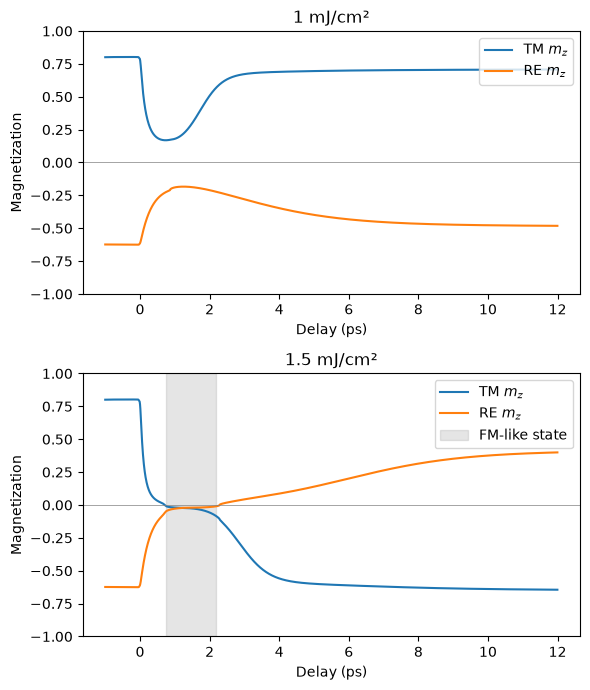

In [8]:
plt.figure(figsize=[6, 3.5 * len(fluences)])
for i, fluence in enumerate(fluences):
    plt.subplot(len(fluences), 1, i + 1)
    plt.plot(delays, results[fluence][:, 0, 2], label="TM $m_z$")
    plt.plot(delays, results[fluence][:, 1, 2], label="RE $m_z$")
    if np.isfinite(windows[fluence][0]):
        plt.axvspan(*windows[fluence], color="gray", alpha=0.2, label="FM-like state")
    plt.axhline(0, color="gray", lw=0.5)
    plt.ylim(-1, 1)
    plt.xlabel("Delay (ps)")
    plt.ylabel("Magnetization")
    plt.title(f"{fluence} mJ/cm²")
    plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

Below the threshold both sublattices demagnetize and recover along their original directions, the TM faster and further than the RE with its larger moment.
Above it the TM sublattice is quenched completely while the RE is still far above its equilibrium; the exchange-relaxation torque transfers the excess angular momentum of the RE into the TM, which crosses zero and is polarized along the RE - the transient ferromagnetic-like state, shaded in the plot - and the RE follows as the electrons cool, so both sublattices end up reversed.
This is Fig. 1 of {cite:t}`raposo2022`.

The switching is converged with the default tolerances of the `ode_options`, which a run with much tighter tolerances confirms for the amplitudes of both sublattices.

In [9]:
fluence = fluences[-1]
maps = {}
for rtol, atol in ((1e-3, 1e-6), (1e-7, 1e-10)):
    llb.ode_options.update({"rtol": rtol, "atol": atol})
    maps[rtol] = llb.get_sublattice_magnetization_map(
        delays, temp_map=temp_maps[fluence], exchange_relaxation=True
    )
llb.ode_options.update({"rtol": 1e-3, "atol": 1e-6})
amplitudes = {}
for rtol, sublattice_map in maps.items():
    amplitudes[rtol] = np.mean(np.linalg.norm(sublattice_map[:, select], axis=-1), axis=1)
deviation = np.max(np.abs(amplitudes[1e-3] - amplitudes[1e-7]))
print(f"largest deviation of the amplitudes: {deviation:.1e}")

largest deviation of the amplitudes: 1.9e-03


## Control: the Conventional LLB

Without `exchange_relaxation=True` the exchange-relaxation torque is off and the conventional two-sublattice LLB remains, the control of {cite:t}`raposo2022` (their Fig. S4).
At the same fluence the TM sublattice is quenched but never reverses: the bath relaxation can only pull it back towards the exchange field of the RE, which points along its original direction, or - if the TM reaches zero in floating point - leave it at the fixed point $m = 0$.

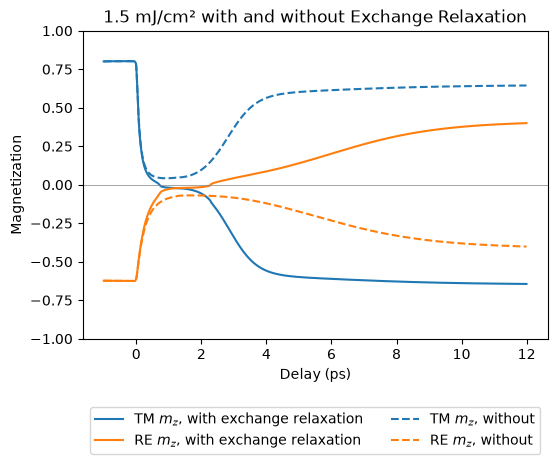

In [10]:
with warnings.catch_warnings():
    # the quenched TM sublattice may stick at the fixed point m = 0
    warnings.simplefilter("ignore")
    sublattice_map = llb.get_sublattice_magnetization_map(delays, temp_map=temp_maps[fluence])
control = np.mean(sublattice_map[:, select], axis=1)

plt.figure(figsize=[6, 4])
plt.plot(delays, results[fluence][:, 0, 2], label="TM $m_z$, with exchange relaxation")
plt.plot(delays, results[fluence][:, 1, 2], label="RE $m_z$, with exchange relaxation")
plt.plot(delays, control[:, 0, 2], "--", color="C0", label="TM $m_z$, without")
plt.plot(delays, control[:, 1, 2], "--", color="C1", label="RE $m_z$, without")
plt.axhline(0, color="gray", lw=0.5)
plt.ylim(-1, 1)
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.title(f"{fluence} mJ/cm² with and without Exchange Relaxation")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.show()

## Switching Diagram

:::{admonition} References {cite}`davies2020,jakobs2022`
:class: seealso
C. S. Davies, T. Janssen, J. H. Mentink, A. Tsukamoto, A. V. Kimel, A. F. G. van der Meer, A. Stupakiewicz, and A. Kirilyuk,
*Pathways for single-shot all-optical switching of magnetization in ferrimagnets*,
[Phys. Rev. Applied 13, 024064 (2020)](https://doi.org/10.1103/PhysRevApplied.13.024064)

F. Jakobs and U. Atxitia,
*Universal criteria for single femtosecond pulse ultrafast magnetization switching in ferrimagnets*,
[Phys. Rev. Lett. 129, 037203 (2022)](https://doi.org/10.1103/PhysRevLett.129.037203)
:::

Finally, the fluence and the duration of the laser pulse are scanned and the out-of-plane magnetization of the TM sublattice at the end of the simulation is shown.
For longer pulses, the electrons transfer more of the absorbed energy to the phonons already during the pulse, so that their peak temperature decreases.
The delay range is adapted to the pulse duration.

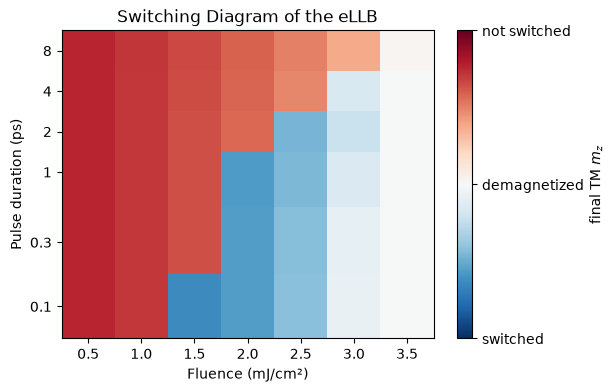

In [11]:
scan_fluences = np.r_[0.5:3.51:0.5]  # mJ/cm^2
scan_widths = np.array([0.1, 0.3, 1, 2, 4, 8])  # ps
final_m_z = np.zeros([len(scan_widths), len(scan_fluences)])
with warnings.catch_warnings():
    # the quenched TM sublattice may stick at the fixed point m = 0
    warnings.simplefilter("ignore")
    for i, width in enumerate(scan_widths):
        delays_scan = np.r_[-2 * width - 1 : 2 * width + 10 : 0.05] * u.ps
        for j, fluence in enumerate(scan_fluences):
            h.excitation = {
                "fluence": [fluence] * u.mJ / u.cm**2,
                "pulse_width": [width] * u.ps,
            }
            temp_map, _ = h.get_temp_map(delays_scan, T_R)
            sublattice_map = llb.get_sublattice_magnetization_map(
                delays_scan, temp_map=temp_map, exchange_relaxation=True
            )
            # final out-of-plane magnetization of the TM averaged over the film
            m_z = sublattice_map[-1, select, 0, 2]
            final_m_z[i, j] = np.mean(m_z)

# edges of the cells, logarithmic for the pulse durations
fluence_edges = np.r_[scan_fluences - 0.25, scan_fluences[-1] + 0.25]
log_widths = np.log10(scan_widths)
width_edges = (
    10
    ** np.r_[
        1.5 * log_widths[0] - 0.5 * log_widths[1],
        (log_widths[1:] + log_widths[:-1]) / 2,
        1.5 * log_widths[-1] - 0.5 * log_widths[-2],
    ]
)

plt.figure(figsize=[6, 4])
plt.pcolormesh(fluence_edges, width_edges, final_m_z, cmap="RdBu_r", vmin=-1, vmax=1)
colorbar = plt.colorbar(label="final TM $m_z$", ticks=[-1, 0, 1])
colorbar.ax.set_yticklabels(["switched", "demagnetized", "not switched"])
plt.yscale("log")
plt.yticks(scan_widths, [f"{width:g}" for width in scan_widths])
plt.minorticks_off()
plt.xlabel("Fluence (mJ/cm²)")
plt.ylabel("Pulse duration (ps)")
plt.title("Switching Diagram of the eLLB")
plt.show()

Below a threshold fluence, the TM sublattice recovers along its original direction, above it the magnetization is switched.
The threshold increases for longer pulses, as the electrons do not become hot enough anymore, and for pulses of several picoseconds the switching dies off.
For the largest fluences, the film is still above the ordering temperature at the end of the simulation, so that the magnetization has not recovered yet.

Qualitatively, this agrees with the experiments of {cite:t}`davies2020`, who found a critical pulse duration for the switching of GdFeCo, which increases from 1.4 ps to more than 6 ps for Gd concentrations between 23% and 26%.
{cite:t}`jakobs2022` showed that the switching requires the magnetization of the TM sublattice to drop below a threshold value, while the RE sublattice still carries enough angular momentum.
In the simple heat model used here, the electrons stay hot for longer than in the paper of {cite:t}`raposo2022`, so that the RE sublattice is also quenched strongly and the TM sublattice needs to be quenched almost completely for switching.
Moreover, the deterministic eLLB neglects thermal fluctuations, which render the switching random if both sublattices cross zero almost simultaneously {cite:p}`davies2020`.